# Nested sampling of a planet's orbit with Gaia astrometry and radial velocities

Notebook 03 found the planet with `fit_astrometry_and_rv_planets` (a periodogram search, then a best fit) and sampled the posterior with MCMC, started at the best fit. This notebook samples the same posterior directly with nested sampling ([dynesty](https://dynesty.readthedocs.io); Speagle 2020), starting from the prior, with no search and no best fit. Nested sampling explores the whole prior, so it finds every significant mode of the posterior (e.g. aliases of the period, or both modes of an ambiguous inclination), and it needs no starting point, burn-in or convergence checks; it also gives the evidence (not used here). The price is more likelihood evaluations than an MCMC started at the best fit. This notebook
1. simulates the Gaia DR5 astrometry and RVs of notebook 03 (the same data),
2. defines physical priors, and the likelihood with gaiamockplus' `log_likelihood_astrometry_and_rv_planets`,
3. samples the posterior with dynesty, and
4. shows the posterior (corner plot) and the maximum-likelihood orbit and RVs.

It needs `gaiamockplus`, `dynesty` and `corner`. The nested sampling takes about 5 minutes.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import dynesty
import corner
from scipy.stats import beta
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(6)            # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the astrometry and the RVs

As in notebook 03 (the same code and random seed): a 3 $M_\mathrm{J}$ planet on a 9 yr orbit around a 0.8 $M_\odot$ star at 100 pc, with Gaia DR5 astrometry and 22 RVs from three instruments (with 3 m/s of jitter).

In [2]:
# the star and the planet: as in notebook 01, with a 3 Jupiter-mass planet
m_star = 0.8               # Msun
parallax = 10.0            # mas
phot_g_mean_mag = 11.1     # G magnitude of a 0.8 Msun main-sequence star at 100 pc
ra, dec = 25.0, -13.0      # deg
pmra, pmdec = 12.0, 30.0   # mas/yr
planet = dict(period=365.25*4.0**1.5/np.sqrt(m_star), Tp=500.0, ecc=0.2,
              Omega=np.radians(110.0), inc=np.radians(60.0), w=np.radians(50.0), m_planet=3*M_JUP)

# Gaia astrometry
ast_data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                          planets=[planet], phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                          c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = ast_data

# three RV datasets: number of RVs, formal uncertainty (km/s), and time range (yr, relative to the reference epoch)
n_rv = [5, 7, 10]
rv_err_set = [0.007, 0.010, 0.010]
time_ranges = [(-10, -4), (-5, 1), (0, 7)]
gamma = np.array([-12.405, -12.380, -12.420])  # systemic velocity of each dataset (km/s)
jitter = 0.003                                 # km/s

t_rvs_yr = np.concatenate([np.sort(rng.uniform(*r, n)) for r, n in zip(time_ranges, n_rv)])
rv_dataset = np.repeat([0, 1, 2], n_rv)        # the dataset of each RV
rv_err = np.repeat(rv_err_set, n_rv)           # formal uncertainties
rv = (gmp.rv_planets_model(t_rvs_yr, m_star, [planet], gamma, c_funcs, rv_dataset=rv_dataset)
      + np.sqrt(rv_err**2 + jitter**2)*rng.normal(0, 1, len(t_rvs_yr)))
rv_data = (t_rvs_yr, rv, rv_err)

a0_true, K_true = gmp.get_planet_a0_mas(m_star, [planet], parallax)[0], gmp.get_planet_K_kms(m_star, [planet])[0]
print(f'astrometry: {len(t_ast_yr)} transits, a0 = {a0_true:.3f} mas, median uncertainty {np.median(ast_err):.3f} mas')
print(f'RVs: {len(rv)} in {len(n_rv)} datasets, K = {1e3*K_true:.1f} m/s')

astrometry: 170 transits, a0 = 0.143 mas, median uncertainty 0.047 mas
RVs: 22 in 3 datasets, K = 42.0 m/s


## 2. Priors and likelihood

The parameters are those of `log_likelihood_astrometry_and_rv_planets` (with `fit_ast_jitter=True`; see notebook 03), except that the planet's mass replaces $a_0$, which follows from the mass, period, parallax and stellar mass. The priors:

| parameter | prior |
|---|---|
| position offsets $\Delta\alpha^*$, $\Delta\delta$; parallax $\varpi$ | uniform, within 2 mas of the no-planet solution |
| proper motion $\mu_{\alpha^*}$, $\mu_\delta$ | uniform, within 2 mas/yr of the no-planet solution |
| period $P$ | log-uniform, 1 to 30 yr |
| eccentricity $e$ | Beta(0.867, 3.03) (Kipping 2013) |
| phase $\phi_p$, $\Omega$, $\omega$ | uniform, 0 to $2\pi$ |
| inclination $i$ | isotropic ($\cos i$ uniform between -1 and 1) |
| planet mass $m_p$ | log-uniform, 0.3 to 30 $M_\mathrm{J}$ |
| systemic velocity of each RV dataset | uniform, within 100 m/s of the dataset's mean RV |
| RV jitter of each dataset | uniform, 0 to 20 m/s |
| astrometric jitter $s$ | uniform, 0 to 0.1 mas |

The no-planet solution (position, proper motion and parallax, from `get_astrometric_chi2_planets` with no planets) only centers the priors: the planet's reflex orbit shifts it by about its size (0.14 mas here), and the prior ranges are far wider than the posterior (~0.01 mas). dynesty draws points in the unit cube, which `prior_transform` maps to the parameters.

In [3]:
# the no-planet solution, to center the priors of the position, proper motion and parallax
_, (ra0, pmra0, dec0, pmdec0, plx0) = gmp.get_astrometric_chi2_planets(*ast_data, [], [], [])
rv_mean = np.array([rv[rv_dataset == k].mean() for k in range(len(n_rv))])

names = ['ra_off', 'dec_off', 'parallax', 'pmra', 'pmdec', 'P', 'e', 'phi_p', 'Omega', 'inc', 'w', 'm_p',
         'gamma_0', 'gamma_1', 'gamma_2', 'jitter_0', 'jitter_1', 'jitter_2', 'ast_jitter']
ndim = len(names)

def prior_transform(u):
    '''parameters (gaiamock units: mas, mas/yr, days, radians, Msun, km/s) from a point u in the unit cube'''
    x = np.empty(ndim)
    x[:5] = np.array([ra0, dec0, plx0, pmra0, pmdec0]) + 4*(u[:5] - 0.5)    # within 2 mas (mas/yr)
    x[5] = 365.25*np.exp(np.log(1.0) + (np.log(30.0) - np.log(1.0))*u[5])   # P: log-uniform, 1 to 30 yr
    x[6] = beta.ppf(u[6], 0.867, 3.03)                                      # e
    x[7], x[8], x[10] = 2*np.pi*u[7], 2*np.pi*u[8], 2*np.pi*u[10]          # phi_p, Omega, w
    x[9] = np.arccos(1 - 2*u[9])                                            # inc: isotropic
    x[11] = M_JUP*np.exp(np.log(0.3) + (np.log(30.0) - np.log(0.3))*u[11])  # m_p: log-uniform, 0.3 to 30 M_Jup
    x[12:15] = rv_mean + 0.2*(u[12:15] - 0.5)                               # systemic velocities: within 0.1 km/s
    x[15:18] = 0.02*u[15:18]                                                # RV jitters: 0 to 0.02 km/s
    x[18] = 0.1*u[18]                                                       # astrometric jitter: 0 to 0.1 mas
    return x

def log_like(x):
    '''the likelihood of notebook 03's MCMC, with a0 computed from the planet mass'''
    theta = x.copy()
    theta[11] = gaiamock.get_a0_mas(period=x[5], m1=m_star, m2=x[11], parallax=x[2], f=0.0)
    return gmp.log_likelihood_astrometry_and_rv_planets(theta, *ast_data, *rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True, marginalize=False)

## 3. Nested sampling

The sampler keeps 400 "live" points drawn from the prior and repeatedly replaces the one with the lowest likelihood by a new point of higher likelihood, so the live points contract onto the posterior. New points are found within multiple ellipsoids that bound the live points (`bound='multi'`), with slice sampling (`sample='rslice'`; in our tests, dynesty's random-walk sampler gave posteriors up to ~30% too narrow in these 19 dimensions). The angles $\phi_p$, $\Omega$ and $\omega$ are periodic. The run stops with dynesty's default criterion (the estimated remaining evidence is small).

In [4]:
sampler = dynesty.NestedSampler(log_like, prior_transform, ndim, nlive=400, bound='multi', sample='rslice', periodic=[7, 8, 10],
                                rstate=np.random.default_rng(6))
start = time.time()
sampler.run_nested(print_progress=False)
runtime = time.time() - start
res = sampler.results
print(f'{runtime/60:.1f} minutes: {res.niter} iterations, {np.sum(res.ncall)} likelihood evaluations')
print(f'ln(evidence) = {res.logz[-1]:.2f} +/- {res.logzerr[-1]:.2f}; information H = {res.information[-1]:.0f} nats')

4.7 minutes: 24095 iterations, 2798205 likelihood evaluations
ln(evidence) = 289.54 +/- 0.55; information H = 52 nats


## 4. The posterior

The nested-sampling points carry weights; `samples_equal` resamples them into equally weighted posterior samples. As in notebook 03, the planet mass and the Campbell elements are shown, with the parallax relative to the no-planet solution; the red lines mark the true values.

24495 samples (effective sample size 4523)


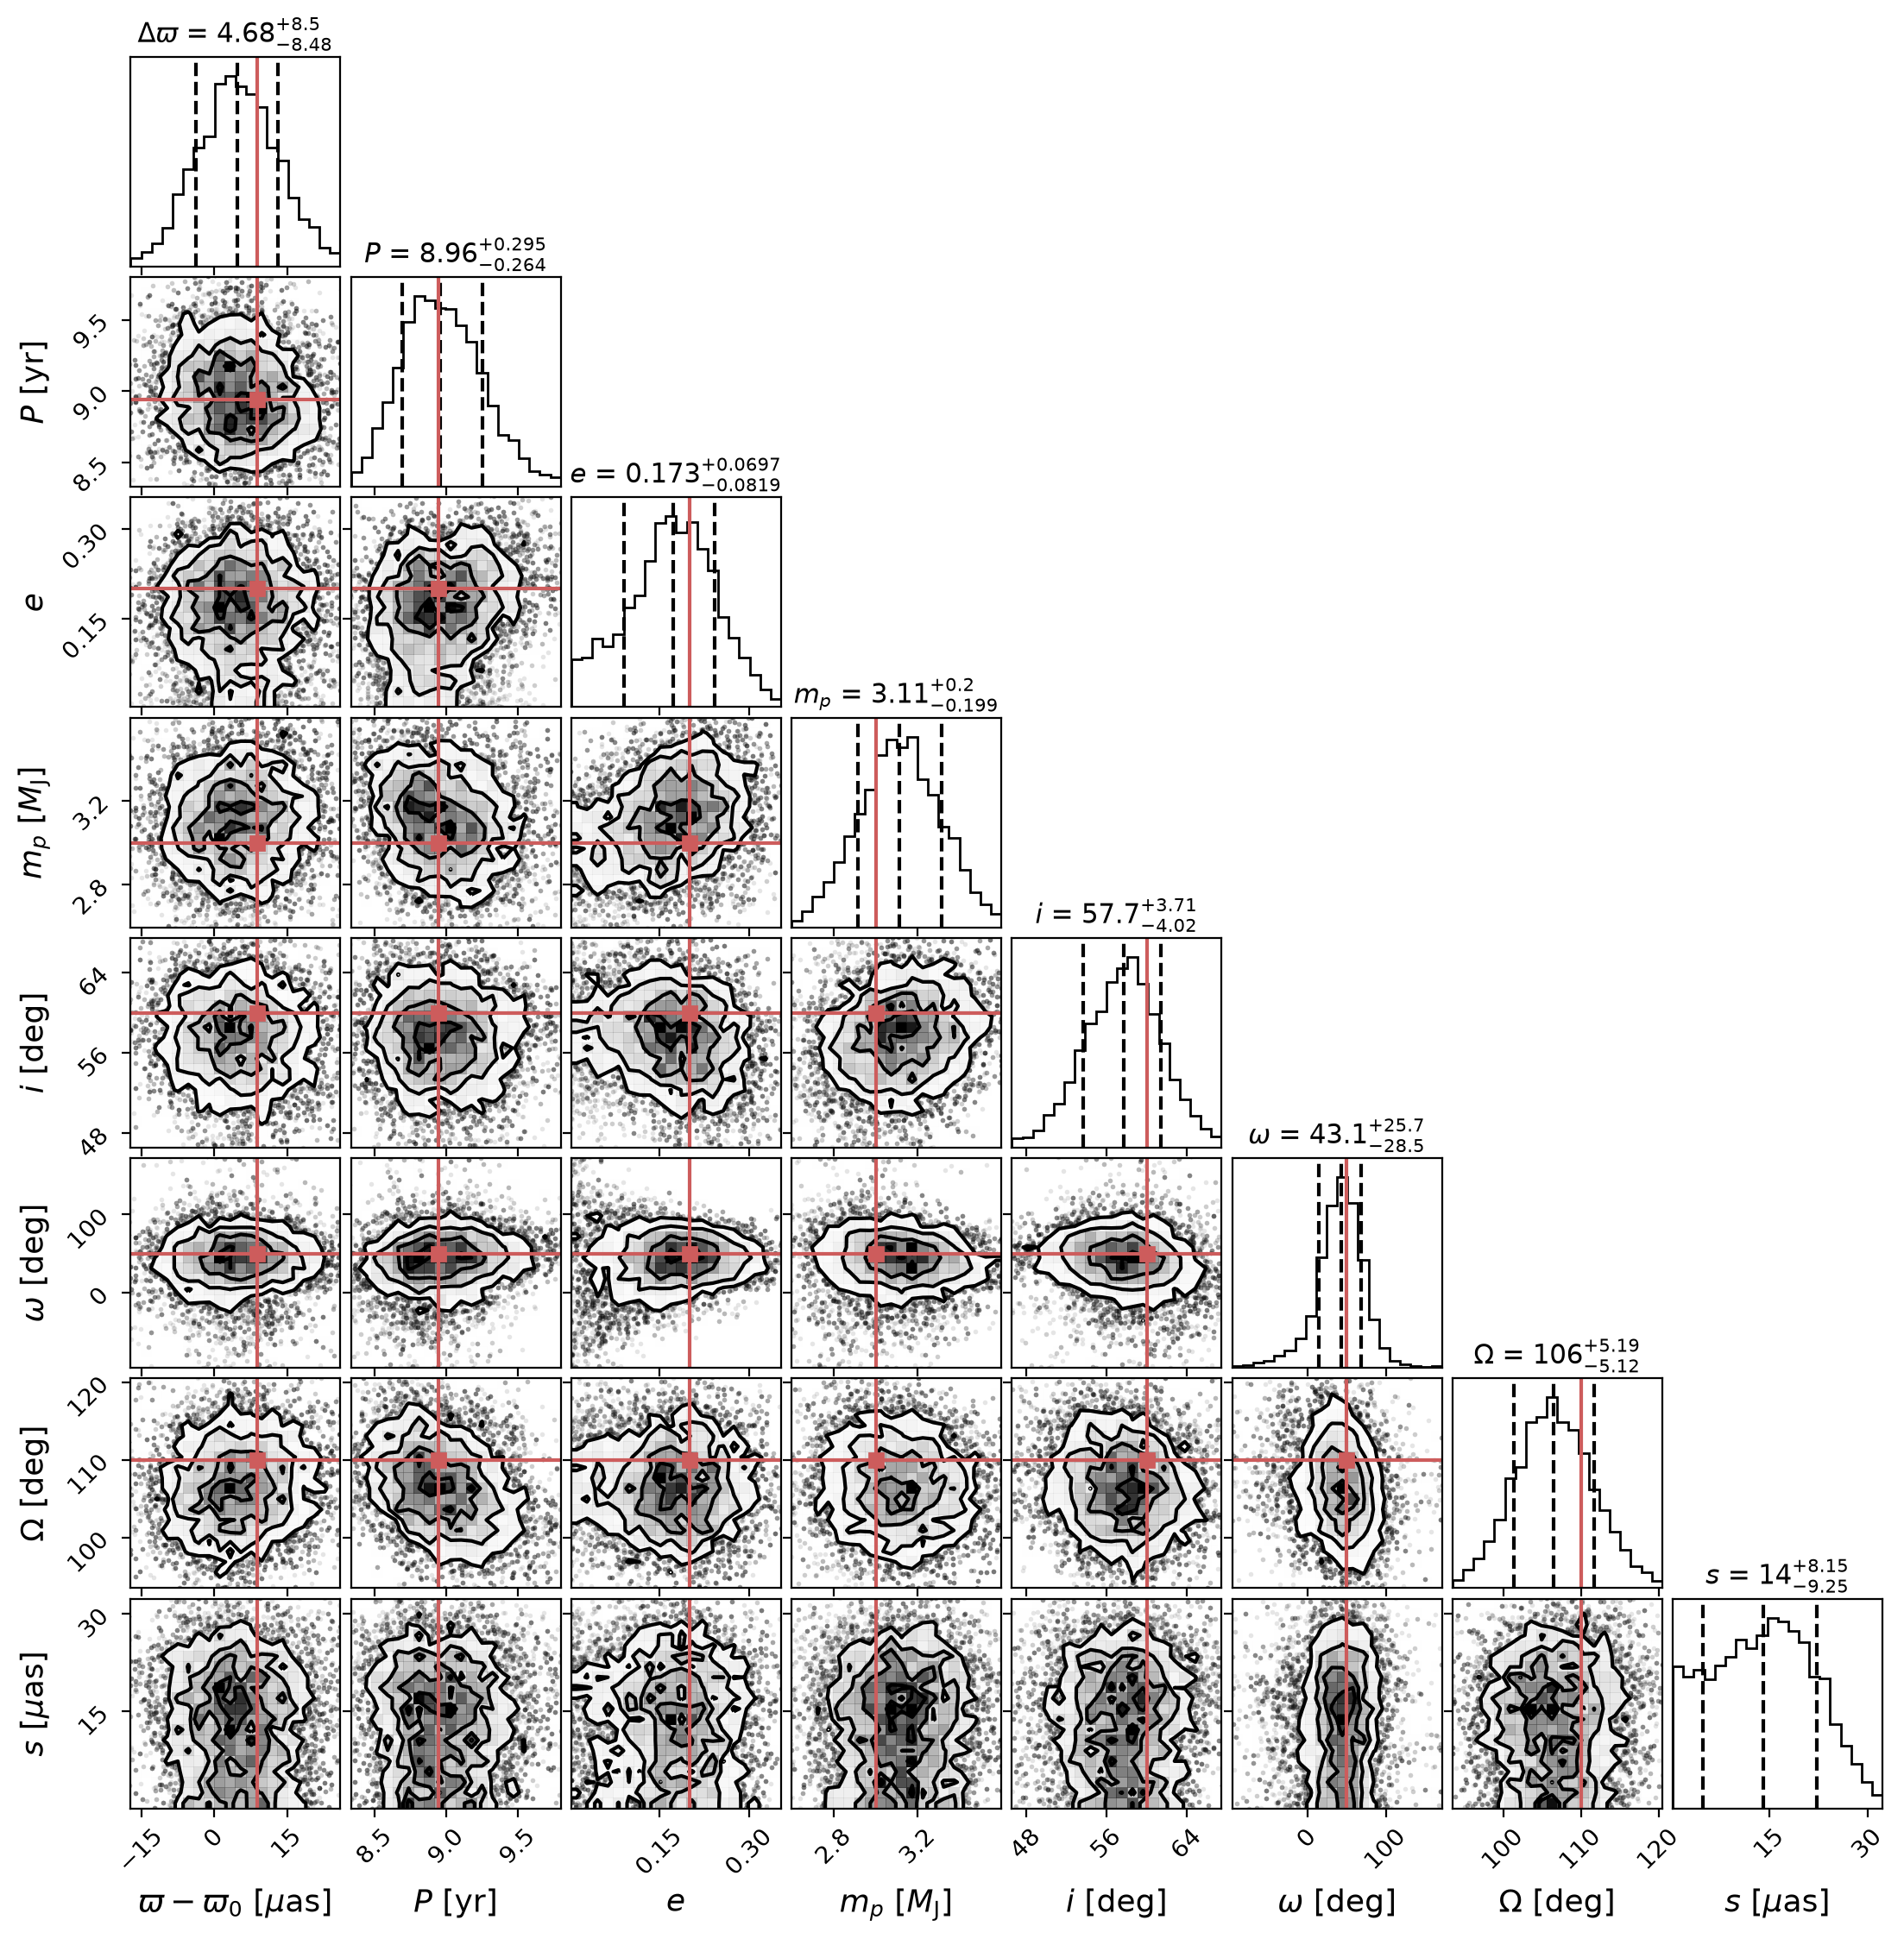

RV jitter [m/s] (true 3): dataset 0: 3.7 (+4.7 / -2.6), dataset 1: 4.0 (+4.5 / -2.8), dataset 2: 4.1 (+4.3 / -2.8)


In [5]:
samples = res.samples_equal(rstate=np.random.default_rng(1))
weights = res.importance_weights()
print(f'{len(samples)} samples (effective sample size {1/np.sum(weights**2):.0f})')

plx_s, P_s, e_s, Omega_s, inc_s, w_s, m_s = (samples[:, k] for k in (2, 5, 6, 8, 9, 10, 11))
w_s = planet['w'] + np.angle(np.exp(1j*(w_s - planet['w'])))              # keep the angles continuous around the truth
Omega_s = planet['Omega'] + np.angle(np.exp(1j*(Omega_s - planet['Omega'])))

corner_samples = np.column_stack([1e3*(plx_s - plx0), P_s/365.25, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s),
                                  1e3*samples[:, 18]])
labels = [r'$\varpi - \varpi_0$ [$\mu$as]', r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]',
          r'$s$ [$\mu$as]']
titles = [r'$\Delta\varpi$', r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$', r'$s$']
truths = [1e3*(parallax - plx0), planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, 60.0, 50.0, 110.0, None]
fig = corner.corner(corner_samples, range=[0.99]*corner_samples.shape[1], labels=labels, titles=titles, truths=truths, truth_color='indianred',
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08, label_kwargs=dict(fontsize=13),
                    title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

lo, med, hi = np.percentile(1e3*samples[:, 15:18], [16, 50, 84], axis=0)
print('RV jitter [m/s] (true 3):', ', '.join(f'dataset {k}: {med[k]:.1f} (+{hi[k] - med[k]:.1f} / -{med[k] - lo[k]:.1f})' for k in range(3)))

The maximum-likelihood point of the run: the photocenter orbit on the sky (as in notebook 03) and the RVs, with each dataset's systemic velocity subtracted (error bars: formal uncertainty and jitter in quadrature).

maximum likelihood: P = 8.91 yr, e = 0.20, m_p = 2.92 M_Jup, inc = 56.2 deg


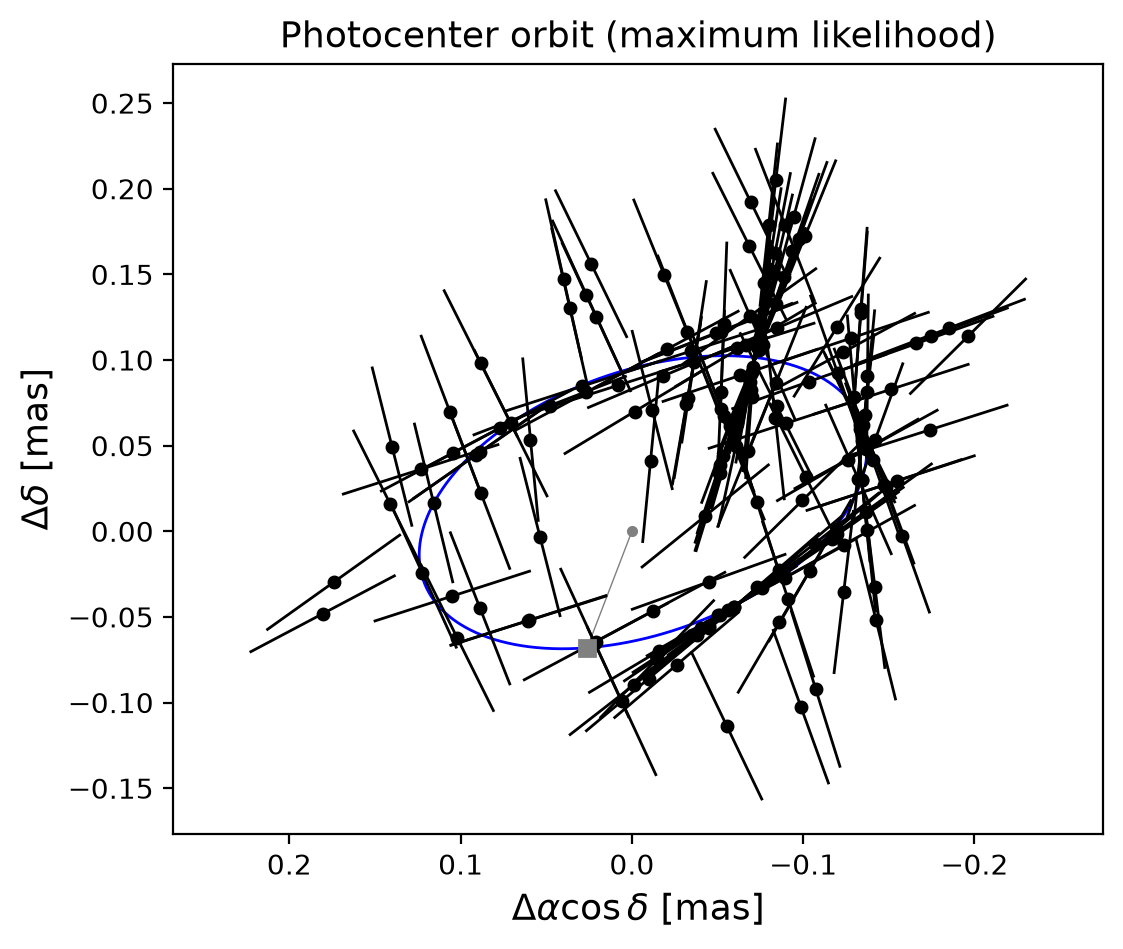

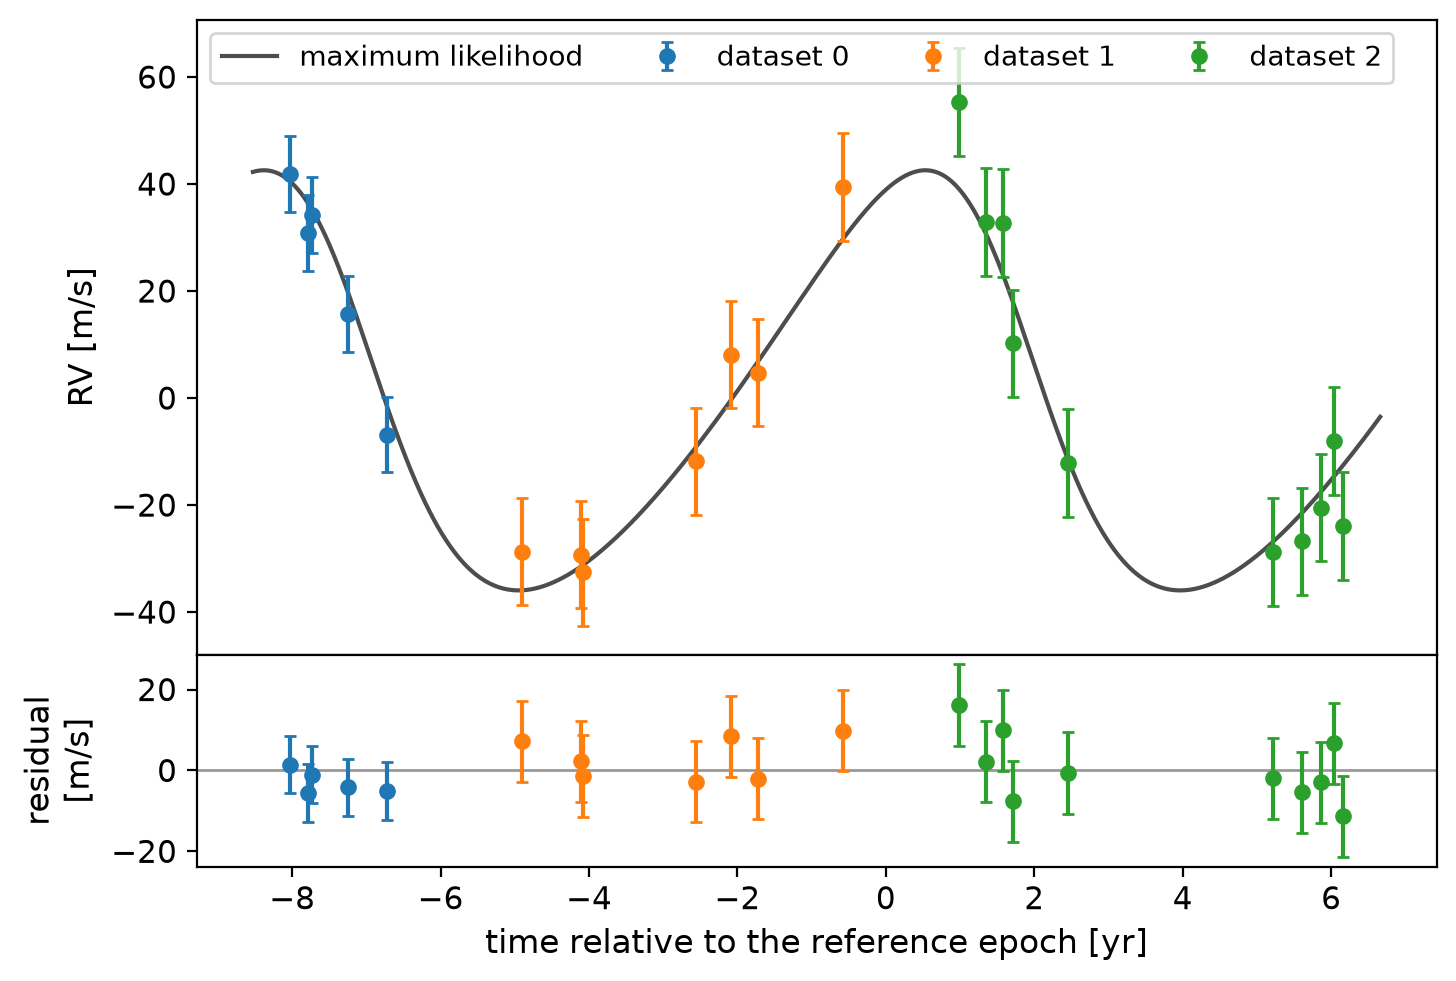

In [6]:
x = res.samples[np.argmax(res.logl)]
a0 = gaiamock.get_a0_mas(period=x[5], m1=m_star, m2=x[11], parallax=x[2], f=0.0)
best = dict(period=x[5], Tp=x[7]*x[5]/(2*np.pi), ecc=x[6], Omega=x[8], inc=x[9], w=x[10], m_planet=x[11])
print(f"maximum likelihood: P = {x[5]/365.25:.2f} yr, e = {x[6]:.2f}, m_p = {x[11]/M_JUP:.2f} M_Jup, inc = {np.degrees(x[9]):.1f} deg")

A, B, F, G = gmp.get_thiele_innes(a0, best['Omega'], best['inc'], best['w'])
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(*ast_data, period=best['period'], ecc=best['ecc'], Tp=best['Tp'], delta_ra=x[0], delta_dec=x[1],
                                     parallax=x[2], pmra=x[3], pmdec=x[4], A=A, B=B, F=F, G=G, data_release='dr5', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title('Photocenter orbit (maximum likelihood)', fontsize=13)
plt.show()

gamma_best, jitter_best = x[12:15], x[15:18]
t_grid = np.linspace(t_rvs_yr.min() - 0.5, t_rvs_yr.max() + 0.5, 2000)
curve = gmp.rv_planets_model(t_grid, m_star, [best], 0.0, c_funcs)
model = gmp.rv_planets_model(t_rvs_yr, m_star, [best], gamma_best, c_funcs, rv_dataset=rv_dataset)
err = np.sqrt(rv_err**2 + jitter_best[rv_dataset]**2)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0))
axes[0].plot(t_grid, 1e3*curve, color='0.3', lw=1.5, zorder=0, label='maximum likelihood')
for k in range(len(n_rv)):
    on = rv_dataset == k
    axes[0].errorbar(t_rvs_yr[on], 1e3*(rv[on] - gamma_best[k]), 1e3*err[on], fmt='o', ms=5, capsize=2, label=f'dataset {k}')
    axes[1].errorbar(t_rvs_yr[on], 1e3*(rv[on] - model[on]), 1e3*err[on], fmt='o', ms=5, capsize=2)
axes[1].axhline(0, color='0.6', lw=1, zorder=0)
axes[0].set_ylabel('RV [m/s]', fontsize=12)
axes[1].set_ylabel('residual\n[m/s]', fontsize=12)
axes[1].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
axes[0].legend(fontsize=10, ncol=4, loc='upper left')
for ax in axes:
    ax.tick_params(labelsize=11)
plt.show()

In [7]:
# posterior summary: median and 68% interval
for label, value, true in zip(['P [yr]', 'e', 'm_p [M_Jup]', 'inc [deg]', 'w [deg]', 'Omega [deg]'], corner_samples[:, 1:7].T, truths[1:7]):
    lo, med, hi = np.percentile(value, [16, 50, 84])
    print(f'{label:12s} {med:8.3f} (+{hi - med:.3f} / -{med - lo:.3f})   true {true:.3f}')

P [yr]          8.956 (+0.295 / -0.264)   true 8.944
e               0.173 (+0.070 / -0.082)   true 0.200
m_p [M_Jup]     3.112 (+0.200 / -0.199)   true 3.000
inc [deg]      57.725 (+3.714 / -4.022)   true 60.000
w [deg]        43.148 (+25.688 / -28.505)   true 50.000
Omega [deg]   106.467 (+5.187 / -5.116)   true 110.000
